# 01 - Análise exploratória dos dados

O conjunto Student Career Success Prediction é analisado quanto à estrutura, distribuição, qualidade e associação entre variáveis. A exploração fornece subsídios para a definição dos problemas de regressão e classificação.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import f_oneway, chi2_contingency

sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/raw/student_career_success_dataset.csv")

## 1. Inspeção inicial

In [2]:
display(df.head())
display(df.tail())
print(f"Dimensões: {df.shape[0]} linhas × {df.shape[1]} colunas")

,Student_ID,Age,Gender,University_Year,Major,Attendance_Percentage,Study_Hours_Per_Week,CGPA,Academic_Performance,Programming_Skill,...,Teamwork,Problem_Solving,English_Proficiency,Interview_Score,Employability_Score,Placement_Status,Company_Tier,Career_Field,Placement_Mode,Starting_Salary_USD
0,ST000001,22,Male,Sophomore,Computer Science,86,21,3.28,Good,9,...,7,8,Advanced,72,231.70,Placed,Tier 1,Backend Developer,Campus Placement,72082
1,ST000002,20,Female,Freshman,Computer Science,64,18,2.53,Poor,6,...,6,5,Basic,59,157.45,Not Placed,No Company,Not Placed,Not Applicable,0
2,ST000003,23,Male,Senior,Information Technology,75,19,2.83,Average,8,...,8,7,Advanced,76,203.45,Placed,Tier 1,IT Support Engineer,Campus Placement,94898
3,ST000004,23,Female,Senior,Information Technology,80,19,2.80,Average,5,...,6,6,Intermediate,67,171.50,Not Placed,No Company,Not Placed,Not Applicable,0
4,ST000005,23,Female,Senior,Software Engineering,73,19,2.93,Average,9,...,8,9,Advanced,82,225.45,Placed,Tier 1,Software Engineer,Internship Conversion,85256


,Student_ID,Age,Gender,University_Year,Major,Attendance_Percentage,Study_Hours_Per_Week,CGPA,Academic_Performance,Programming_Skill,...,Teamwork,Problem_Solving,English_Proficiency,Interview_Score,Employability_Score,Placement_Status,Company_Tier,Career_Field,Placement_Mode,Starting_Salary_USD
49995,ST049996,22,Male,Sophomore,Software Engineering,76,13,2.92,Average,9,...,5,8,Advanced,86,224.80,Placed,Tier 1,Software Engineer,Campus Placement,103525
49996,ST049997,21,Male,Senior,Artificial Intelligence,84,21,2.90,Average,7,...,9,7,Intermediate,69,190.70,Not Placed,No Company,Not Placed,Not Applicable,0
49997,ST049998,20,Female,Junior,Software Engineering,86,25,3.31,Good,9,...,6,9,Advanced,86,243.15,Placed,Tier 1,DevOps Engineer,Campus Placement,102324
49998,ST049999,20,Male,Junior,Software Engineering,92,15,3.05,Average,10,...,6,10,Advanced,87,245.25,Placed,Tier 1,DevOps Engineer,Referral,82095
49999,ST050000,23,Female,Junior,Computer Science,73,24,3.08,Average,8,...,6,7,Advanced,84,221.20,Placed,Tier 1,Software Engineer,Campus Placement,100199


Dimensões: 50000 linhas × 29 colunas


In [3]:
display(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Student_ID             50000 non-null  str    
 1   Age                    50000 non-null  int64  
 2   Gender                 50000 non-null  str    
 3   University_Year        50000 non-null  str    
 4   Major                  50000 non-null  str    
 5   Attendance_Percentage  50000 non-null  int64  
 6   Study_Hours_Per_Week   50000 non-null  int64  
 7   CGPA                   50000 non-null  float64
 8   Academic_Performance   50000 non-null  str    
 9   Programming_Skill      50000 non-null  int64  
 10  Projects_Completed     50000 non-null  int64  
 11  Certifications         50000 non-null  int64  
 12  Hackathons             50000 non-null  int64  
 13  GitHub_Profile         50000 non-null  str    
 14  Internships            50000 non-null  int64  
 15  Leadership_Ex

None

## 2. Tipos e estatísticas

In [4]:
display(df.dtypes.to_frame("Tipo"))
display(df.describe().T)

,Tipo
Student_ID,str
Age,int64
Gender,str
University_Year,str
Major,str
Attendance_Percentage,int64
Study_Hours_Per_Week,int64
CGPA,float64
Academic_Performance,str
Programming_Skill,int64


,count,mean,std,min,25%,50%,75%,max
Age,50000.0,21.262900,2.041163,18.0,20.00,21.00,22.00,30.00
Attendance_Percentage,50000.0,81.409640,9.709519,50.0,75.00,82.00,88.00,100.00
Study_Hours_Per_Week,50000.0,21.528160,6.974810,5.0,17.00,21.00,26.00,45.00
CGPA,50000.0,3.106043,0.290351,2.0,2.91,3.11,3.31,4.00
Programming_Skill,50000.0,7.137160,1.507194,1.0,6.00,7.00,8.00,10.00
Projects_Completed,50000.0,8.620560,2.505408,0.0,7.00,9.00,10.00,15.00
Certifications,50000.0,1.715660,1.368301,0.0,1.00,2.00,3.00,8.00
Hackathons,50000.0,3.093940,1.660774,0.0,2.00,3.00,4.00,10.00
Internships,50000.0,4.048880,1.005719,0.0,3.00,4.00,5.00,5.00
Resume_Score,50000.0,96.045740,7.331565,44.0,95.00,100.00,100.00,100.00


## 3. Variáveis categóricas

In [5]:
categoricas = df.select_dtypes(include="object").columns.tolist()
for col in categoricas:
    print(f"\n### {col}")
    if col != "Student_ID": print(df[col].value_counts().to_string())

C:\Users\Felipe Erik\AppData\Local\Temp\ipykernel_29284\2896958856.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categoricas = df.select_dtypes(include="object").columns.tolist()



### Student_ID

### Gender
Gender
Male      24533
Female    24465
Other      1002

### University_Year
University_Year
Junior       14870
Senior       12658
Sophomore    12634
Freshman      9838

### Major
Major
Computer Science           12407
Software Engineering        7516
Artificial Intelligence     7505
Data Science                6116
Cybersecurity               4975
Information Technology      4906
Business Analytics          4027
Electrical Engineering      2548

### Academic_Performance
Academic_Performance
Average      28890
Good         18168
Poor          1956
Excellent      986

### GitHub_Profile
GitHub_Profile
Yes    40680
No      9320

### Leadership_Experience
Leadership_Experience
No     30403
Yes    19597

### LinkedIn_Profile
LinkedIn_Profile
Yes    35917
No     14083

### English_Proficiency
English_Proficiency
Advanced        39640
Intermediate     9720
Basic             640

### Placement_Status
Placement_Status
Placed        39040
Not Placed    10960

### Comp

## 4. Valores ausentes

In [6]:
missing = pd.DataFrame({"Quantidade": df.isna().sum(), "Porcentagem (%)": (df.isna().mean()*100).round(2)})
display(missing)
print("Total de células ausentes:", int(df.isna().sum().sum()))

,Quantidade,Porcentagem (%)
Student_ID,0,0.0
Age,0,0.0
Gender,0,0.0
University_Year,0,0.0
Major,0,0.0
Attendance_Percentage,0,0.0
Study_Hours_Per_Week,0,0.0
CGPA,0,0.0
Academic_Performance,0,0.0
Programming_Skill,0,0.0


Total de células ausentes: 0


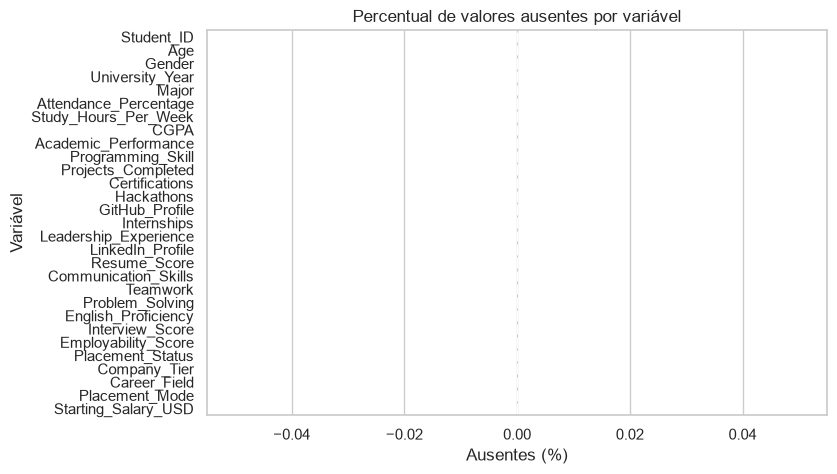

In [7]:
plt.figure(figsize=(8,5))
sns.barplot(x=missing["Porcentagem (%)"].values, y=missing.index, color="C0")
plt.title("Percentual de valores ausentes por variável")
plt.xlabel("Ausentes (%)")
plt.ylabel("Variável")
plt.show()

## 5. Outliers pelo método IQR

In [8]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
outlier_rows=[]
for col in numeric_cols:
    q1=df[col].quantile(.25); q3=df[col].quantile(.75); iqr=q3-q1
    lower=q1-1.5*iqr; upper=q3+1.5*iqr
    n=((df[col]<lower)|(df[col]>upper)).sum()
    outlier_rows.append([col,int(n),round(100*n/len(df),2),lower,upper])
outliers=pd.DataFrame(outlier_rows,columns=["Variável","Outliers","%","Limite inferior","Limite superior"])
display(outliers.sort_values("Outliers",ascending=False))

,Variável,Outliers,%,Limite inferior,Limite superior
15,Starting_Salary_USD,10960,21.92,18343.750,143371.750
9,Resume_Score,6354,12.71,87.500,107.500
0,Age,2033,4.07,17.000,25.000
5,Projects_Completed,806,1.61,2.500,14.500
14,Employability_Score,545,1.09,142.975,287.975
13,Interview_Score,490,0.98,44.500,112.500
3,CGPA,267,0.53,2.310,3.910
1,Attendance_Percentage,249,0.50,55.500,107.500
2,Study_Hours_Per_Week,244,0.49,3.500,39.500
12,Problem_Solving,192,0.38,3.000,11.000


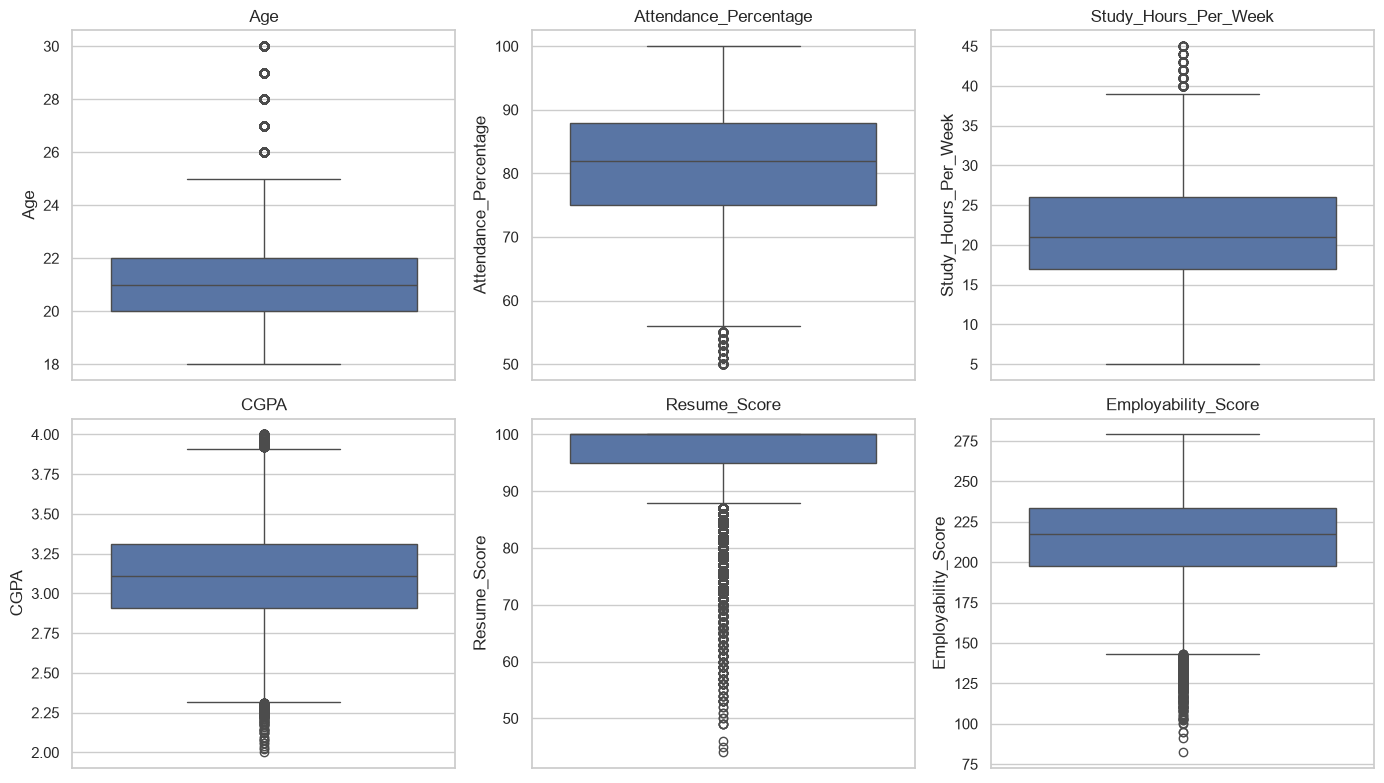

In [9]:
selected=["Age","Attendance_Percentage","Study_Hours_Per_Week","CGPA","Resume_Score","Employability_Score"]
fig,axes=plt.subplots(2,3,figsize=(14,8))
for ax,col in zip(axes.flat,selected):
    sns.boxplot(y=df[col],ax=ax,color="C0")
    ax.set_title(col)
plt.tight_layout(); plt.show()

## 6. Correlação

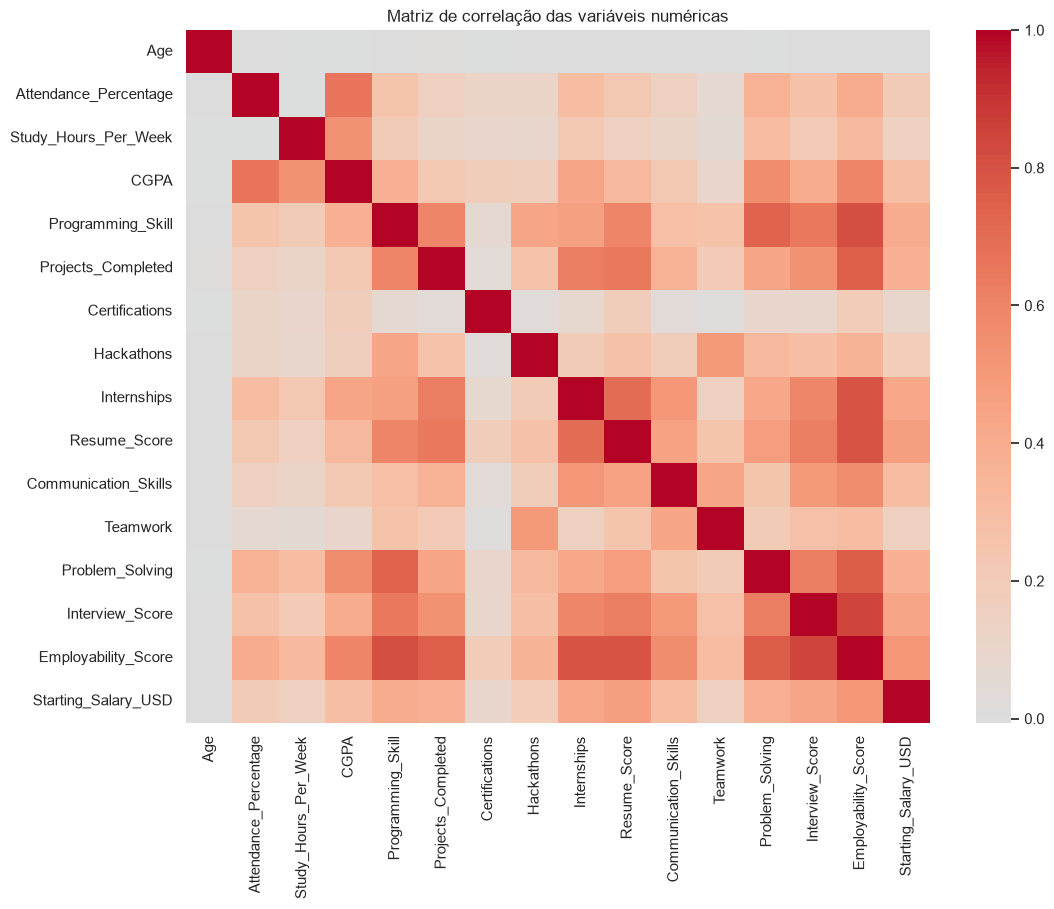

Top correlações com Employability_Score:


,Correlação
Interview_Score,0.844578
Programming_Skill,0.814310
Resume_Score,0.790519
Internships,0.789657
Problem_Solving,0.764074
Projects_Completed,0.752465
CGPA,0.601362
Communication_Skills,0.556664
Starting_Salary_USD,0.516361
Attendance_Percentage,0.403592


In [10]:
corr=df[numeric_cols].corr()
plt.figure(figsize=(12,9))
sns.heatmap(corr,center=0,cmap="coolwarm")
plt.title("Matriz de correlação das variáveis numéricas")
plt.show()

print("Top correlações com Employability_Score:")
display(corr["Employability_Score"].drop("Employability_Score").sort_values(ascending=False).to_frame("Correlação"))

## 7. Visualizações principais

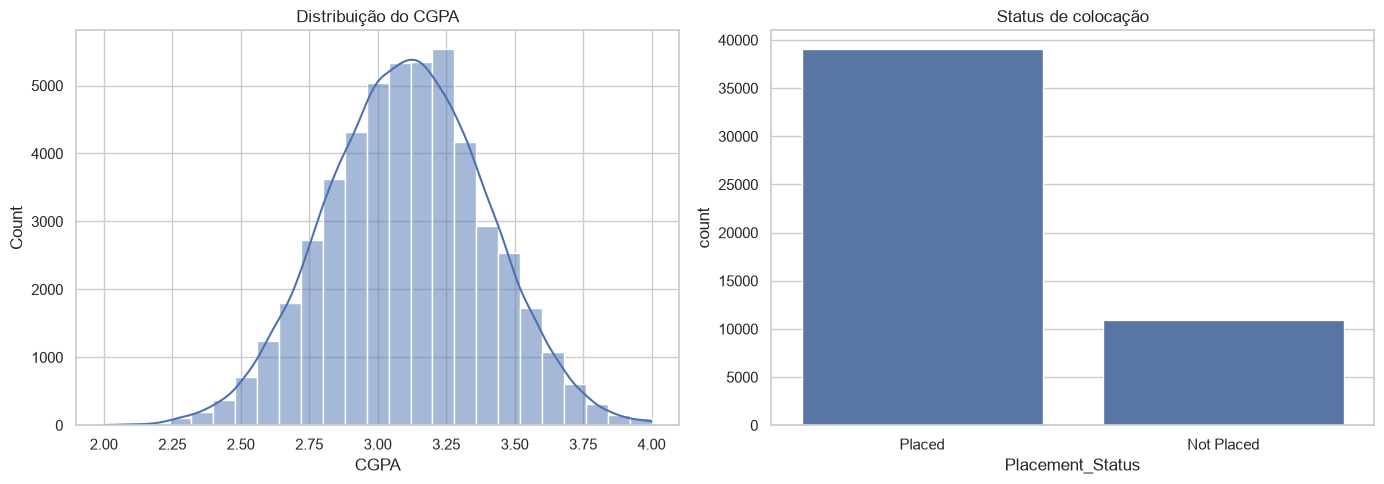

In [11]:
fig,axes=plt.subplots(1,2,figsize=(14,5))
sns.histplot(df["CGPA"],bins=25,kde=True,ax=axes[0],color="C0"); axes[0].set_title("Distribuição do CGPA")
sns.countplot(data=df,x="Placement_Status",ax=axes[1],color="C0"); axes[1].set_title("Status de colocação")
plt.tight_layout(); plt.show()

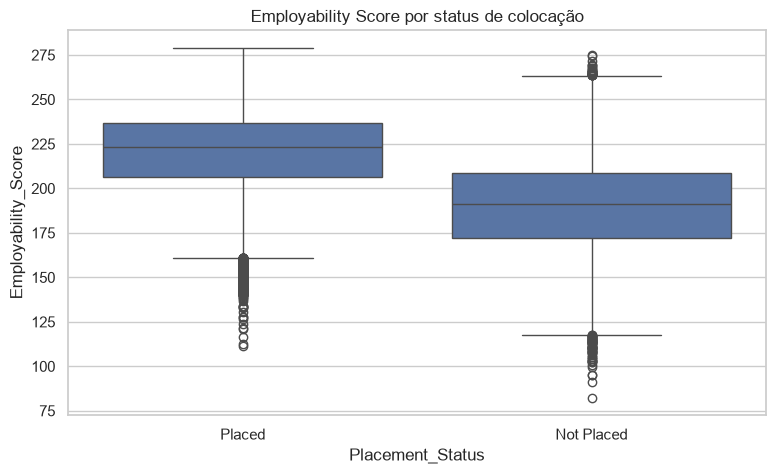

In [12]:
plt.figure(figsize=(9,5)); sns.boxplot(data=df,x="Placement_Status",y="Employability_Score",color="C0"); plt.title("Employability Score por status de colocação"); plt.show()

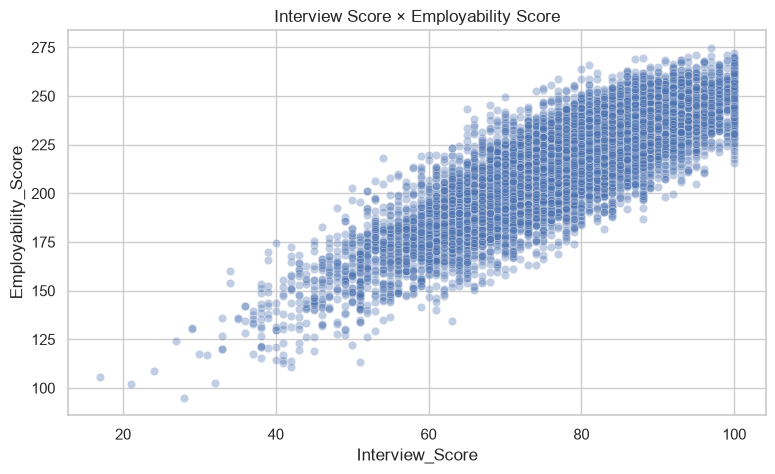

In [13]:
plt.figure(figsize=(9,5)); sns.scatterplot(data=df.sample(10000,random_state=42),x="Interview_Score",y="Employability_Score",alpha=.35,color="C0"); plt.title("Interview Score × Employability Score"); plt.show()

## 8. Relação com classificação: Placement_Status

In [14]:
print(df["Placement_Status"].value_counts())
print(df["Placement_Status"].value_counts(normalize=True).mul(100).round(2))

Placement_Status
Placed        39040
Not Placed    10960
Name: count, dtype: int64
Placement_Status
Placed        78.08
Not Placed    21.92
Name: proportion, dtype: float64


In [15]:
anova=[]
for col in numeric_cols:
    if col == "Starting_Salary_USD": continue
    a=df.loc[df.Placement_Status=="Placed",col]; b=df.loc[df.Placement_Status=="Not Placed",col]
    f,p=f_oneway(a,b); anova.append([col,f,p])
anova_df=pd.DataFrame(anova,columns=["Variável","F","p_valor"]).sort_values("p_valor")
display(anova_df)

,Variável,F,p_valor
1,Attendance_Percentage,1769.153812,0.000000e+00
3,CGPA,3941.990051,0.000000e+00
5,Projects_Completed,6728.404546,0.000000e+00
4,Programming_Skill,7970.350172,0.000000e+00
7,Hackathons,1477.233655,0.000000e+00
10,Communication_Skills,4094.117885,0.000000e+00
9,Resume_Score,11034.023759,0.000000e+00
8,Internships,9079.999004,0.000000e+00
14,Employability_Score,14385.344028,0.000000e+00
13,Interview_Score,9659.409352,0.000000e+00


In [16]:
chi=[]
for col in [c for c in categoricas if c not in ["Student_ID","Placement_Status"]]:
    tab=pd.crosstab(df[col],df.Placement_Status); stat,p,dof,exp=chi2_contingency(tab); chi.append([col,stat,p,dof])
chi_df=pd.DataFrame(chi,columns=["Variável","Qui-quadrado","p_valor","gl"]).sort_values("p_valor")
display(chi_df)

,Variável,Qui-quadrado,p_valor,gl
3,Academic_Performance,2709.173224,0.000000e+00,3
2,Major,2130.197958,0.000000e+00,7
7,English_Proficiency,4301.386655,0.000000e+00,2
8,Company_Tier,50000.000000,0.000000e+00,3
9,Career_Field,50000.000000,0.000000e+00,16
10,Placement_Mode,50000.000000,0.000000e+00,4
5,Leadership_Experience,692.205789,1.481221e-152,1
4,GitHub_Profile,534.096465,3.628667e-118,1
1,University_Year,8.633980,3.457475e-02,3
6,LinkedIn_Profile,0.242870,6.221411e-01,1


## 9. Observações para as próximas etapas

- Não há valores ausentes no arquivo original.
- `Student_ID` é identificador e não deve ser usado como preditor.
- `Placement_Status`, `Company_Tier`, `Career_Field`, `Placement_Mode` e `Starting_Salary_USD` representam resultados/estado de colocação e devem ser tratados com cuidado para evitar vazamento de informação.
- Para regressão, foi selecionado `Employability_Score`, por ser uma variável numérica contínua com 2.892 valores distintos e sem zeros estruturais.
- Para classificação, foi selecionado `Placement_Status`, com 39.040 estudantes colocados (78,08%) e 10.960 não colocados (21,92%).
